# Python 기초 — 자료 구조와 Python 프로그래밍

HaLab Quest 3장 · 분석 기본기 익히기 **Lv.2 Python 길** 자료예요. RNA-seq analysis 교재의 **W2 R 기초**와 같은 순서로, 같은 일을 Python으로 해요.

- **목표:** 데이터를 불러오고, 자료형을 구분하고, 조건으로 고르고, 간단한 함수를 써요.
- **어디서:** 연구실 서버의 Jupyter Hub에서 **Python 3 커널**로 열어요 (Lab manual 서버 매뉴얼 참고). [이 노트북 파일(python-basics.ipynb)](python-basics.ipynb)을 받아서 Jupyter Hub에 올리면 돼요.
- **어떻게:** 위에서부터 셀을 하나씩 실행해요 (`Shift + Enter`). 숫자를 바꿔 다시 실행해 보면서 결과가 어떻게 바뀌는지 봐요.
- **데이터:** 이 노트북의 표는 모두 만든 예제예요. 실제 환자 · 미발표 데이터는 노트북을 다른 사람과 나누거나 AI에 넣지 않아요.

> 우리 연구실 기준: 처음부터 끝까지 혼자 짜지 못해도 괜찮아요. 코드를 읽고 필요한 부분을 고칠 수 있으면 돼요.

## 0. 노트북 쓰는 법

| 하고 싶은 것 | 방법 |
|---|---|
| 셀 실행하고 다음 셀로 | `Shift + Enter` |
| 위 · 아래에 새 셀 | 셀 밖(파란 테두리)에서 `A` · `B` |
| 코드 셀 ↔ 글 셀 | `Y` · `M` |
| 처음부터 다시 | 메뉴 Kernel → Restart Kernel and Run All Cells |

- 셀의 마지막 줄 값은 `print()` 없이도 아래에 보여요.
- 스크립트는 이렇게 **노트북으로 남겨요.** 코드 바로 아래에 결과(표 · 그림 · 오류)가 같이 남아서 나중에 다시 보거나 교수님께 보여 드리기 쉬워요.

## 1. 패키지 불러오기

Python은 기본 기능이 작고, 필요한 기능은 **패키지**로 불러와 써요. 분석에서 가장 많이 쓰는 셋은 이거예요.

| 패키지 | 하는 일 | 관례적인 줄임말 |
|---|---|---|
| NumPy | 숫자 배열, 계산 | `np` |
| pandas | 표(데이터 프레임) | `pd` |
| Matplotlib | 그림 | `plt` |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print(np.__version__, pd.__version__)

2.5.4 3.1.0


## 2. Python의 자료형

### 1) 기본 자료형: 숫자 · 문자 · 논리

R의 `numeric` · `character` · `logical`에 해당해요. Python은 정수(`int`)와 실수(`float`)를 나눠요.

In [2]:
age = 35          # 정수 int
bmi = 22.5        # 실수 float
sex = "F"         # 문자열 str ('' 도 같아요)
recur = True      # 논리 bool (True / False, 첫 글자 대문자)

type(age), type(bmi), type(sex), type(recur)

(int, float, str, bool)

#### 자료형 확인과 변환

- 확인: `type()`, `isinstance()`
- 변환: `int()`, `float()`, `str()`, `bool()`

In [3]:
print(int("42") + 1)        # 문자 → 숫자
print(str(3.14) + " 입니다")  # 숫자 → 문자
print(float("1e-5"))         # 과학적 표기도 돼요
isinstance(bmi, float)

43
3.14 입니다
1e-05


True

### 2) 리스트 (list): 여러 값을 순서대로

R의 벡터와 비슷하지만, **자료형이 섞여도 돼요.** 대괄호 `[ ]`로 만들어요.

> ⚠️ R과 가장 크게 다른 점: **Python은 0부터 셉니다.** 첫 번째 값은 `[0]`, 범위 `[1:3]`은 1번, 2번만 (끝 3은 빠져요).

In [4]:
genes = ["TP53", "BRCA1", "EGFR", "MYC", "KRAS"]

print(genes[0])      # 첫 번째 → TP53
print(genes[-1])     # 마지막 → KRAS
print(genes[1:3])    # 1, 2번 → ['BRCA1', 'EGFR']
print(len(genes))    # 길이

TP53
KRAS
['BRCA1', 'EGFR']
5


In [5]:
genes.append("PTEN")      # 끝에 추가
print(genes)
print("EGFR" in genes)    # 들어 있나?
print(sorted(genes))      # 정렬한 새 리스트 (원본은 그대로)

['TP53', 'BRCA1', 'EGFR', 'MYC', 'KRAS', 'PTEN']
True
['BRCA1', 'EGFR', 'KRAS', 'MYC', 'PTEN', 'TP53']


리스트끼리 `+` 하면 **이어 붙여져요.** 숫자 계산은 아래 NumPy 배열로 해요.

In [6]:
[1, 2, 3] + [10, 20, 30]

[1, 2, 3, 10, 20, 30]

### 3) 딕셔너리 (dict): 이름표가 붙은 값

R의 이름 붙은 리스트(`list(a = 1, b = "x")`)와 비슷해요. `{이름: 값}`으로 만들고 이름으로 꺼내요.

In [7]:
sample = {"id": "S1", "age": 35, "sex": "M", "genes": ["TP53", "EGFR"]}

print(sample["age"])       # 이름으로 꺼내기
sample["bmi"] = 19         # 새 항목 추가
print(sample.keys())
sample

35
dict_keys(['id', 'age', 'sex', 'genes', 'bmi'])


{'id': 'S1', 'age': 35, 'sex': 'M', 'genes': ['TP53', 'EGFR'], 'bmi': 19}

### 4) NumPy 배열: 숫자 벡터 · 행렬

R의 숫자 벡터처럼 **같은 자료형**만 담고, **한꺼번에 계산**돼요 (벡터 연산).

In [8]:
x = np.array([1, 2, 3, 4, 5])
print(x * 2)          # 모든 값에 2를 곱함
print(x + x)          # 같은 위치끼리 더함
print(x.mean(), x.sum(), x.std())
print(np.arange(1, 6))  # R의 1:5 (끝 6은 빠져요)

[ 2  4  6  8 10]
[ 2  4  6  8 10]
3.0 15 1.4142135623730951
[1 2 3 4 5]


#### 행렬 (2차원 배열)

발현 행렬(유전자 × 시료)이 바로 이런 모양이에요.

In [9]:
m = np.arange(1, 13).reshape(3, 4)   # 3행 4열
print(m)
print("차원:", m.shape)
print("1행 2열(0부터 세면 [0, 1]):", m[0, 1])
print("두 번째 열 전체:", m[:, 1])
print("행마다 합:", m.sum(axis=1))   # axis=1 → 행 방향 (R의 apply(m, 1, sum))
print("열마다 합:", m.sum(axis=0))   # axis=0 → 열 방향 (R의 apply(m, 2, sum))

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
차원: (3, 4)
1행 2열(0부터 세면 [0, 1]): 2
두 번째 열 전체: [ 2  6 10]
행마다 합: [10 26 42]
열마다 합: [15 18 21 24]


### 5) 데이터 프레임 (pandas DataFrame)

- **여러 자료형**을 함께 담는 2차원 표. 실제 분석에서 가장 많이 써요.
- 열 하나는 `Series`예요.

In [10]:
df = pd.DataFrame({
    "x": [35, 42, 50],
    "y": ["M", "F", "F"],
    "z": [True, False, True],
})
df

,x,y,z
0,35,M,True
1,42,F,False
2,50,F,True


In [11]:
# 구조 확인 (R의 str)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   x       3 non-null      int64
 1   y       3 non-null      str  
 2   z       3 non-null      bool 
dtypes: bool(1), int64(1), str(1)
memory usage: 183.0 bytes


In [12]:
print(df.shape)          # (행, 열) = R의 dim
print(list(df.columns))  # 열 이름 = R의 names
df.dtypes

(3, 3)
['x', 'y', 'z']


x    int64
y      str
z     bool
dtype: object

> 문자열 열의 자료형은 pandas 버전에 따라 `object` 또는 `str`로 보여요. 둘 다 문자열이에요.

In [13]:
# 열 이름 바꾸기
df.columns = ["age", "sex", "recur"]
df

,age,sex,recur
0,35,M,True
1,42,F,False
2,50,F,True


#### 인덱싱: `loc`(이름으로) · `iloc`(위치로)

| R | pandas | 뜻 |
|---|---|---|
| `df[1, 2]` | `df.iloc[0, 1]` | 1행 2열 (위치, 0부터) |
| `df[1:2, ]` | `df.iloc[0:2]` | 1~2행 |
| `df$age` | `df["age"]` | age 열 |
| `df[df$age > 40, ]` | `df[df["age"] > 40]` | 조건으로 행 고르기 |

In [14]:
print(df.iloc[0, 1])        # 1행 2열 → 'M'
print(df.iloc[0:2])         # 1~2행
df["age"]                   # age 열 (Series)

M
   age sex  recur
0   35   M   True
1   42   F  False


0    35
1    42
2    50
Name: age, dtype: int64

In [15]:
# 열 추가
df["BMI"] = [19, 35, 25]

# 조건으로 행 고르기 (R의 subset)
df[df["BMI"] > 30]

,age,sex,recur,BMI
1,42,F,False,35


In [16]:
# 조건 두 개: & (그리고), | (또는), 각 조건은 괄호로 감싸요
df[(df["sex"] == "F") & (df["recur"])]

,age,sex,recur,BMI
2,50,F,True,25


In [17]:
# 정렬 (R의 df[order(df$BMI), ])
df.sort_values("BMI")

,age,sex,recur,BMI
0,35,M,True,19
2,50,F,True,25
1,42,F,False,35


In [18]:
# 내림차순, 여러 열 기준
df.sort_values(["sex", "BMI"], ascending=[True, False])

,age,sex,recur,BMI
1,42,F,False,35
2,50,F,True,25
0,35,M,True,19


### 6) 범주형 (R의 factor)

그룹 이름처럼 정해진 값만 오는 열은 `category`로 바꾸면 **순서를 정할 수 있어요.** 그림의 x축 순서, 모델의 기준 그룹이 이 순서를 따라요.

In [19]:
group = pd.Series(["Control", "Treat", "Control", "Treat", "Treat"])
group = pd.Categorical(group, categories=["Control", "Treat"], ordered=True)
print(group)
print(pd.Series(group).value_counts())   # 그룹마다 개수 (R의 table)

['Control', 'Treat', 'Control', 'Treat', 'Treat']
Categories (2, str): ['Control' < 'Treat']
Treat      3
Control    2
Name: count, dtype: int64


## 3. Python의 연산

### 1) 산술 연산자

| 연산 | 기호 | R과 다른 점 |
|---|---|---|
| 더하기 · 빼기 · 곱하기 · 나누기 | `+ - * /` | 같아요 |
| 거듭제곱 | `**` | R은 `^` |
| 몫 · 나머지 | `//` · `%` | R은 `%/%` · `%%` |

In [20]:
print(7 / 2, 7 // 2, 7 % 2, 2 ** 10)
print(np.log2(np.array([1, 2, 4, 8])))   # log2 변환 (발현값에서 자주 써요)

3.5 3 1 1024
[0. 1. 2. 3.]


### 2) 비교 · 논리 연산자

- 비교: `==` `!=` `>` `>=` `<` `<=`
- 값 하나: `and` `or` `not`
- 배열 · 열(여러 값): `&` `|` `~` (각 조건은 괄호로)

In [21]:
expr = np.array([0.5, 3.2, 8.1, 0.0, 12.4])
print(expr > 1)
print((expr > 1) & (expr < 10))
print(np.where(expr > 1))       # 조건을 만족하는 위치 (R의 which, 0부터)
print(expr[expr > 1])           # 조건을 만족하는 값만

[False  True  True False  True]
[False  True  True False False]
(array([1, 2, 4]),)
[ 3.2  8.1 12.4]


## 4. Python 프로그래밍 기초

### 1) 함수

#### 기본 함수 · 통계 함수

In [22]:
values = np.array([2.1, 3.4, 1.8, 5.6, 4.2])
print("평균", values.mean(), "중앙값", np.median(values))
print("표준편차", values.std(ddof=1))   # ddof=1 → 표본 표준편차 (R의 sd와 같음)
print("최소 · 최대", values.min(), values.max())
print("반올림", np.round(values.mean(), 2))

평균 3.4199999999999995 중앙값 3.4
표준편차 1.5594870951694342
최소 · 최대 1.8 5.6
반올림 3.42


> `np.std()`의 기본값은 `ddof=0`(모집단 표준편차)이라 R의 `sd()`와 값이 달라요. 표본이면 `ddof=1`을 붙여요. pandas의 `.std()`는 처음부터 `ddof=1`이에요.

#### 직접 만드는 함수: `def`

들여쓰기(빈칸 4개)로 함수의 몸통을 표시해요. R의 `{ }` 역할이에요.

In [23]:
def cv(x):
    """변동계수(%) = 표준편차 / 평균 × 100"""
    return np.std(x, ddof=1) / np.mean(x) * 100

round(cv(values), 1)

np.float64(45.6)

In [24]:
def fold_change(treat, control, log=True):
    fc = np.mean(treat) / np.mean(control)
    return np.log2(fc) if log else fc

print(fold_change([8, 9, 10], [2, 2.5, 3]))
print(fold_change([8, 9, 10], [2, 2.5, 3], log=False))

1.84799690655495
3.6


### 2) if / elif / else

In [25]:
p = 0.003
if p < 0.001:
    print("***")
elif p < 0.01:
    print("**")
elif p < 0.05:
    print("*")
else:
    print("ns")

**


### 3) for / while

In [26]:
for g in ["TP53", "EGFR", "MYC"]:
    print(g, len(g))

TP53 4
EGFR 4
MYC 3


In [27]:
# 번호와 값을 같이: enumerate (번호는 0부터)
for i, g in enumerate(["TP53", "EGFR", "MYC"]):
    print(i, g)

0 TP53
1 EGFR
2 MYC


In [28]:
n = 1
while n < 100:
    n = n * 2
n

128

#### 리스트 컴프리헨션: 한 줄짜리 for

R의 `sapply`처럼 리스트를 한 번에 바꿀 때 써요.

In [29]:
genes = ["tp53", "egfr", "myc"]
[g.upper() for g in genes]

['TP53', 'EGFR', 'MYC']

In [30]:
# 조건을 붙여서 고르기
[g for g in genes if len(g) > 3]

['tp53', 'egfr']

### 4) 그룹마다 요약: `groupby` (R의 `tapply` · `aggregate`)

In [31]:
meta = pd.DataFrame({
    "sample": ["S1", "S2", "S3", "S4", "S5", "S6"],
    "group":  ["Control", "Control", "Control", "Treat", "Treat", "Treat"],
    "batch":  ["B1", "B2", "B1", "B2", "B1", "B2"],
    "age":    [35, 42, 50, 38, 45, 61],
})
meta.groupby("group")["age"].mean()

group
Control    42.333333
Treat      48.000000
Name: age, dtype: float64

In [32]:
# 여러 요약을 한 번에
meta.groupby("group")["age"].agg(["count", "mean", "std"])

,count,mean,std
group,,,
Control,3,42.333333,7.505553
Treat,3,48.000000,11.789826


In [33]:
# 두 변수로 나눠 세기 (그룹과 배치가 잘 섞였는지 확인할 때)
pd.crosstab(meta["group"], meta["batch"])

batch,B1,B2
group,,
Control,2,1
Treat,1,2


### 5) 간단한 그림

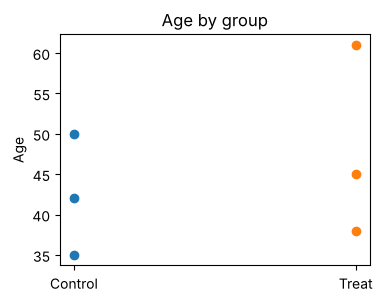

In [34]:
fig, ax = plt.subplots(figsize=(4, 3))
for i, (g, sub) in enumerate(meta.groupby("group")):
    ax.scatter([i] * len(sub), sub["age"], label=g)
ax.set_xticks([0, 1], ["Control", "Treat"])
ax.set_ylabel("Age")
ax.set_title("Age by group")
plt.show()

> 논문 그림은 3장 **Figure 만들기**에서 다뤄요. 여기서는 데이터가 맞게 들어왔는지 빠르게 보는 정도면 충분해요.

## 5. 패키지 설치

| | 명령 | 예 |
|---|---|---|
| PyPI (공식 저장소) | `pip install 패키지` | `pip install scanpy` |
| conda | `conda install -c conda-forge 패키지` | |

- 노트북 셀 안에서는 앞에 `%`를 붙여 `%pip install 패키지`로 설치해요.
- 서버에서는 공용 환경을 망가뜨리지 않게, **설치 전에 Lab manual의 서버 사용 규칙을 먼저** 봐요.
- 오믹스 분석에 자주 쓰는 패키지: `scanpy`(단일세포) · `anndata` · `pydeseq2`(bulk DE) · `seaborn`(그림)

## 6. 작업 폴더와 파일 입출력

### 1) 작업 폴더

노트북은 **노트북 파일이 있는 폴더**를 작업 폴더로 써요. 상대 경로(`data/xxx.csv`)를 쓰면 다른 사람 컴퓨터에서도 그대로 돌아가요.

In [35]:
from pathlib import Path

print(Path.cwd())                    # 지금 작업 폴더 (R의 getwd)
Path("results").mkdir(exist_ok=True)  # 폴더 만들기 (이미 있으면 그대로)

/home/halab/my_project/notebooks


#### 권장하는 폴더 구조

```
my_project/
├── notebooks/   ← 분석 노트북 (.ipynb), 순서대로 번호: 1_qc.ipynb, 2_de.ipynb …
├── rawdata/     ← 원본 데이터 (절대 수정하지 않기)
├── analysis/    ← 전처리한 중간 결과
└── results/     ← 최종 표 · 그림
```

### 2) 파일 읽기와 쓰기 (CSV / TSV)

In [36]:
# 쓰기 (index=False: 행 번호는 빼고 저장)
meta.to_csv("results/meta.csv", index=False)

# 읽기
meta2 = pd.read_csv("results/meta.csv")
meta2.head()   # 처음 5행 (R의 head)

,sample,group,batch,age
0,S1,Control,B1,35
1,S2,Control,B2,42
2,S3,Control,B1,50
3,S4,Treat,B2,38
4,S5,Treat,B1,45


In [37]:
# TSV(탭으로 나눈 파일)는 sep="\t"
meta.to_csv("results/meta.tsv", sep="\t", index=False)
pd.read_csv("results/meta.tsv", sep="\t").shape

(6, 4)

> 엑셀 파일은 `pd.read_excel("파일.xlsx")`로 읽어요 (`openpyxl` 패키지 필요).

## 7. R ↔ Python 한눈에

| 하는 일 | R | Python |
|---|---|---|
| 벡터 · 배열 | `c(1, 2, 3)` | `np.array([1, 2, 3])` |
| 1부터 5 | `1:5` | `np.arange(1, 6)` |
| 첫 번째 값 | `x[1]` | `x[0]` |
| 길이 | `length(x)` | `len(x)` |
| 표 만들기 | `data.frame(...)` | `pd.DataFrame({...})` |
| 구조 | `str(df)` | `df.info()` |
| 열 하나 | `df$age` | `df["age"]` |
| 조건으로 행 | `subset(df, age > 40)` | `df[df["age"] > 40]` |
| 정렬 | `df[order(df$age), ]` | `df.sort_values("age")` |
| 그룹 요약 | `tapply(df$age, df$group, mean)` | `df.groupby("group")["age"].mean()` |
| 개수 세기 | `table(x)` | `x.value_counts()` |
| CSV 읽기 | `read.csv("a.csv")` | `pd.read_csv("a.csv")` |
| 도움말 | `?mean` | `help(np.mean)` 또는 `np.mean?` |

## 8. 다 했다면

**작은 표 하나를 불러와서 원하는 행만 골라 저장해 봐요.**

1. 아래 셀이 만든 `practice_expr.csv`를 `pd.read_csv()`로 읽어요.
2. `group`이 `"Treat"`이고 `expr`가 5보다 큰 행만 골라요.
3. `expr` 기준 내림차순으로 정렬해서 `results/practice_selected.csv`로 저장해요.

막히면 위 **5) 데이터 프레임**을 다시 보고, 그래도 막히면 Slack `#help-study`에 이 노트북과 오류 메시지를 같이 올려 주세요.

In [38]:
# 연습용 표 만들기 (만든 예제 데이터)
rng = np.random.default_rng(1)
practice = pd.DataFrame({
    "gene":  [f"G{i}" for i in range(1, 11)],
    "group": ["Control"] * 5 + ["Treat"] * 5,
    "expr":  np.round(rng.uniform(0, 10, 10), 2),
})
practice.to_csv("practice_expr.csv", index=False)
practice

,gene,group,expr
0,G1,Control,5.12
1,G2,Control,9.50
2,G3,Control,1.44
3,G4,Control,9.49
4,G5,Control,3.12
5,G6,Treat,4.23
6,G7,Treat,8.28
7,G8,Treat,4.09
8,G9,Treat,5.50
9,G10,Treat,0.28


In [39]:
# 여기에 직접 써 보세요